Apply exhaustive Grid Search hyperparameter optimization for machine learning algorithms, automating model tuning with cross-validation and parallel processing to identify the best-performing parameter sets.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

In [3]:
np.random.seed(42)
X_raw, y_raw = make_classification(
    n_samples=1200,
    n_features=10,
    n_informative=7,
    n_redundant=3,
    n_classes=3,
    weights=[0.60, 0.25, 0.15], # Imbalanced diagnostic distribution
    random_state=42
)

In [4]:
feature_names = [f"biomarker_{i+1}" for i in range(10)]
df_clinical = pd.DataFrame(X_raw, columns=feature_names)
df_clinical['diagnostic_class'] = y_raw

In [18]:
X = df_clinical.drop(columns=['diagnostic_class'])
y = df_clinical['diagnostic_class']

In [19]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

In [20]:
preprocessor = ColumnTransformer(
    transformers=[('num_scaler', StandardScaler(), feature_names)]
)

In [21]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

In [22]:
param_grid = {
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__max_iter': [100, 150],
    'classifier__max_leaf_nodes': [15, 31],
    'classifier__l2_regularization': [0.0, 1.0]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=1,  
    verbose=0,
    return_train_score=True
)

In [ ]:
t0 = time.perf_counter()
grid_search.fit(X, y)  
t1 = time.perf_counter()

In [25]:
print("--- Exhaustive Grid Search Optimization Results ---")
print(f"Total Execution Time      : {(t1 - t0):.2f} seconds")
print(f"Best Macro F1-Score (CV)  : {grid_search.best_score_:.4f}")
print("Optimal Parameter Set:")
for param, val in grid_search.best_params_.items():
    print(f"  • {param.replace('classifier__', '')}: {val}")

--- Exhaustive Grid Search Optimization Results ---
Total Execution Time      : 31.70 seconds
Best Macro F1-Score (CV)  : 0.8005
Optimal Parameter Set:
  • l2_regularization: 0.0
  • learning_rate: 0.1
  • max_iter: 150
  • max_leaf_nodes: 31


In [26]:
cv_results = pd.DataFrame(grid_search.cv_results_)
top_models = cv_results.sort_values(by='mean_test_score', ascending=False).head(5)

In [27]:
df_top = pd.DataFrame({
    'Rank': range(1, len(top_models) + 1),
    'Mean CV F1': top_models['mean_test_score'].round(4),
    'Std CV F1': top_models['std_test_score'].round(4),
    'Params': top_models['params'].apply(lambda x: {k.replace('classifier__', ''): v for k, v in x.items()})
}).set_index('Rank')

In [28]:
print("\n--- Top Model Configurations ---")
print(df_top[['Mean CV F1', 'Std CV F1']])


--- Top Model Configurations ---
      Mean CV F1  Std CV F1
Rank                       
1         0.8005     0.0291
2         0.7985     0.0236
3         0.7980     0.0103
4         0.7964     0.0101
5         0.7958     0.0157


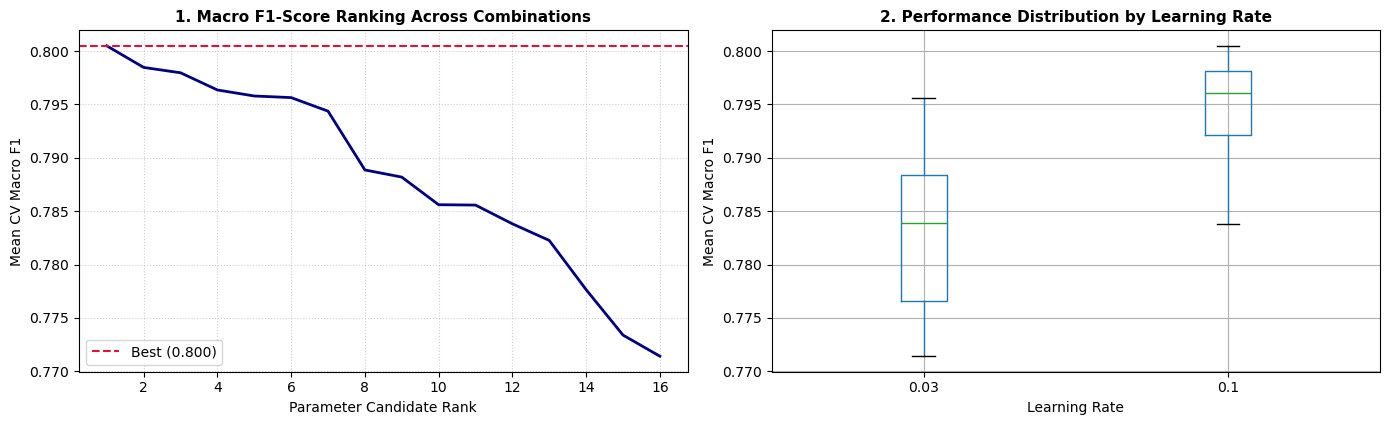

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sorted_scores = cv_results['mean_test_score'].sort_values(ascending=False).values
axes[0].plot(range(1, len(sorted_scores) + 1), sorted_scores, color='navy', lw=2)
axes[0].axhline(grid_search.best_score_, color='crimson', linestyle='--', label=f'Best ({grid_search.best_score_:.3f})')
axes[0].set_title("1. Macro F1-Score Ranking Across Combinations", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Parameter Candidate Rank")
axes[0].set_ylabel("Mean CV Macro F1")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

cv_results['learning_rate'] = cv_results['param_classifier__learning_rate'].astype(str)
cv_results.boxplot(column='mean_test_score', by='learning_rate', ax=axes[1], grid=True)
axes[1].set_title("2. Performance Distribution by Learning Rate", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Mean CV Macro F1")
plt.suptitle("")

plt.tight_layout()
plt.show()